In [1]:
import os, mne, scipy, pickle
import hmp
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib

In [2]:
main_dir = '/Users/cl2030/Library/CloudStorage/OneDrive-RutgersUniversity/projects/PEERS/'
data_dir = os.path.join(main_dir, 'data')

# convert data

In [3]:
# define parameters
task = 'task-ltpFR2'
sess = 'ses-0'
subjects = ['sub-LTP246', 'sub-LTP269', 'sub-LTP279', 'sub-LTP285', 'sub-LTP295', 
            'sub-LTP303', 'sub-LTP310', 'sub-LTP322', 'sub-LTP323', 'sub-LTP327']
subj_files = [os.path.join(data_dir, '%s', '%s', '%s_%s-epo.fif')%(subj, sess, subj, sess) for subj in subjects]

# define epoch info
event_id = dict(Word = 1)
cond_code = list(event_id.values())
cond_name = list(event_id.keys())
sfreq = 100

# aggregate epoch data
epoch_data = hmp.utils.read_mne_data(subj_files,
                                     epoched  = True,
                                     sfreq    = sfreq,
                                     subj_idx = subjects,
                                     event_id = event_id,
                                     scale    = 1000,
                                     rt_col   = 'RT_update',
                                     pick_channels = 'eeg',
                                     lower_limit_RT = 0.5,
                                     upper_limit_RT = 3,
                                     tmin = -0.2,
                                     tmax = 3,
                                     baseline = (-0.2, -0.002),
                                    )

Processing participant /Users/cl2030/Library/CloudStorage/OneDrive-RutgersUniversity/projects/PEERS/data/sub-LTP246/ses-0/sub-LTP246_ses-0-epo.fif's epoched eeg
Reading /Users/cl2030/Library/CloudStorage/OneDrive-RutgersUniversity/projects/PEERS/data/sub-LTP246/ses-0/sub-LTP246_ses-0-epo.fif ...
    Found the data of interest:
        t =    -200.00 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 12 columns
513 matching events found
No baseline correction applied
0 projection items activated
Resampling data at 100
Applying reaction time trim to keep RTs between 0.5 and 3 seconds
415 RTs kept of 513 clean epochs
415 trials were retained for participant /Users/cl2030/Library/CloudStorage/OneDrive-RutgersUniversity/projects/PEERS/data/sub-LTP246/ses-0/sub-LTP246_ses-0-epo.fif
End sampling frequency is 100 Hz
Processing participant /Users/cl2030/Library/CloudStorage/OneDrive-RutgersUniversity/projects/PEERS/data/sub-LTP269/ses-0/sub-LTP269_ses-0-epo.fif

/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/utils.py:305: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'epochs' ('epochs',) The recommendation is to set join explicitly for this case.
  epoch_data = xr.concat(epoch_data, dim = xr.DataArray(subj_idx, dims='participant'),
/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/utils.py:305: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'samples' ('samples',) The recommendation is to set join explicitly for this case.
  epoch_data = xr.concat(epoch_da

In [5]:
# Dimensions: participant x epochs x channels x samples
print(epoch_data.data.shape); print()
print(epoch_data['RT_update'].max().data)


(10, 504, 125, 300)

2998.0


In [6]:
epoch_data.info

<bound method Dataset.info of <xarray.Dataset> Size: 2GB
Dimensions:        (participant: 10, epochs: 504, channels: 125, samples: 300)
Coordinates: (12/16)
  * participant    (participant) <U10 400B 'sub-LTP246' ... 'sub-LTP327'
  * epochs         (epochs) int64 4kB 0 1 2 3 4 5 6 ... 505 507 509 510 511 512
    subject        (participant, epochs) object 40kB 'LTP246' 'LTP246' ... nan
    trial_type     (participant, epochs) object 40kB 'REC_WORD' ... nan
    block          (participant, epochs) float64 40kB 1.0 1.0 nan ... nan nan
    item_name      (participant, epochs) object 40kB 'HERO' 'COTTAGE' ... nan
    ...             ...
    resp_time      (participant, epochs) float64 40kB 2.646e+03 1.95e+03 ... nan
    resp_acc       (participant, epochs) float64 40kB 1.0 1.0 nan ... nan nan
    enc_pos        (participant, epochs) float64 40kB 5.0 6.0 nan ... nan nan
    RT_update      (participant, epochs) float64 40kB 2.646e+03 1.95e+03 ... nan
  * channels       (channels) <U4 2kB 'E1

In [7]:
# read info for sensor location
info = mne.io.read_info(subj_files[0])
positions = info

In [8]:
# transform data for hmp
hmp_data = hmp.utils.transform_data(epoch_data, apply_standard=True, n_comp=10)

In [9]:
# cpus = 14
init = hmp.models.hmp(hmp_data,
                      epoch_data,
                      sfreq = epoch_data.sfreq,
                      event_width = 100,
                      distribution = 'gamma',
                      shape = 2,
                      #cpus  = cpus
                     )

  0%|          | 0/150 [00:00<?, ?it/s]


Event found at sample 2
Events at [  2 149]
lkh change: inf
Transition event 1 found around sample 2

Event found at sample 43
Events at [  3  43 149]
lkh change: 2644.0965419587446
Transition event 2 found around sample 43

Event found at sample 88
Events at [  3  36  88 149]
lkh change: 453.05920458390756
Transition event 3 found around sample 88

Event found at sample 115
Events at [  3  35  81 115 149]
lkh change: 66.36395585720675
Transition event 4 found around sample 115

Event found at sample 131
Events at [  3  32  67 100 131 149]
lkh change: -918.0506762056157

Event found at sample 136
Events at [  3  32  70 104 136 149]
lkh change: -864.2582194964489

Event found at sample 139
Events at [  3  33  72 106 139 149]
lkh change: -826.7118373624908

Event found at sample 141
Events at [  3  33  74 108 141 149]
lkh change: -786.4848290372065

All events found, refitting final combination.


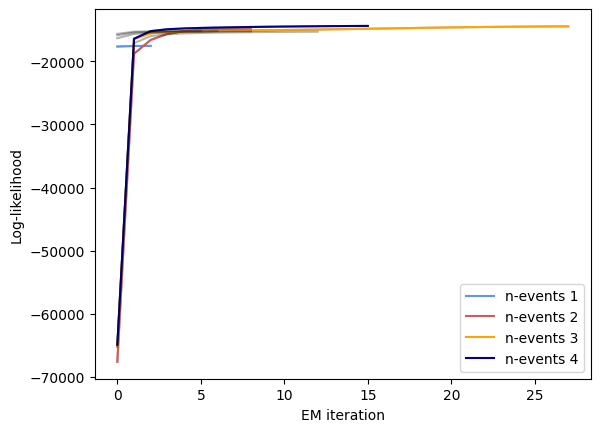

Estimating 4 events model
parameters estimated for 4 events model


In [10]:
# estimate maximal model using fit
max_model = init.fit(step=1, diagnostic=True)

In [11]:
n_events = len(max_model['event'])
print(n_events)
backward_model = init.backward_estimation(max_events = n_events)

4
Estimating all solutions for maximal number of events (4) with 1 pre-defined starting point and 0 random starting points
Estimating all solutions for 3 events
Estimating all solutions for 2 events
Estimating all solutions for 1 events


/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/models.py:1177: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'stage' ('stage',) The recommendation is to set join explicitly for this case.
  event_loo_results = xr.concat(event_loo_results, dim="n_events")
/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/models.py:1177: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'event' ('event',) The recommendation is to set join explicitly for this case.
  event_loo_results = xr.concat(event_loo_results, dim=

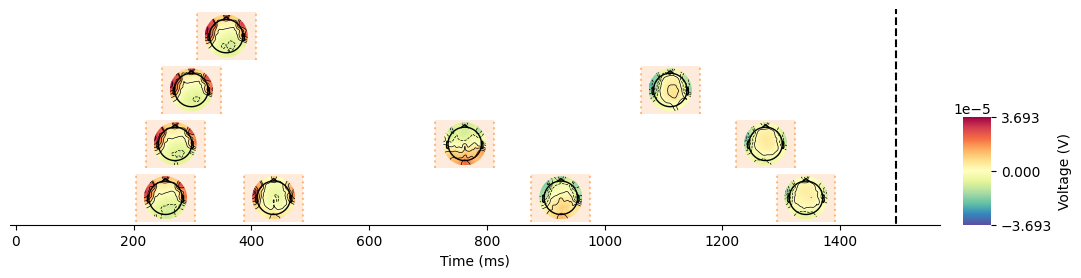

In [12]:
hmp.visu.plot_topo_timecourse(epoch_data,      # epoch data
                              backward_model,  # backward model estimation
                              info,            # position info of the electrodes
                              init,            # initialized model
                              as_time = True,
                              magnify = 1,
                              sensors = False)

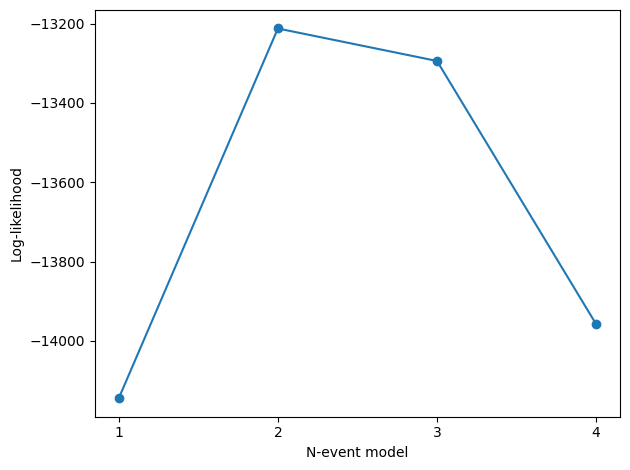

In [13]:
plt.plot(backward_model.n_events, backward_model.likelihoods, 'o-')
plt.ylabel('Log-likelihood')
plt.xlabel('N-event model')
plt.xticks(np.arange(1,n_events+1,1))
plt.tight_layout()
# fname = os.path.join(fig_dir, 'events_prob_%s.png') %(group)
# plt.savefig(fname)
plt.show()

# loocv

In [14]:
# cpus = 14
loocv_model = hmp.loocv.loocv(init,
                              hmp_data,
                              backward_model,
                              # cpus = cpus
                             )


IMPORTANT:  This loocv procedure is incorrect in the sense that an initial estimate
is used to inform both the fit of the left-out participant and the other participants.
This means that they are not fully independent, unless the initial estimate is
based on the literature or another task. However, it does give a very good initial
idea of the correct loocv procedure and is relatively quick.

To do loocv correctly, use loocv_backward or the general loocv_func,
which calculate the initial estimate for every fold by applying
backward estimation or your own function, respectively.

LOOCV started for 1 model(s)
	LOOCV for backward estimation models with [4 3 2 1] event(s)
	  Estimating backward estimation model with 4 event(s)
		Calculating fit for participant sub-LTP246
		Calculating fit for participant sub-LTP269
		Calculating fit for participant sub-LTP279
		Calculating fit for participant sub-LTP285
		Calculating fit for participant sub-LTP295
		Calculating fit for participant sub-LTP3

[TtestResult(statistic=np.float64(3.6502723638019443), pvalue=np.float64(0.002657638071272308), df=np.int64(9)),
 TtestResult(statistic=np.float64(-1.3284595815056348), pvalue=np.float64(0.8916376595316454), df=np.int64(9)),
 TtestResult(statistic=np.float64(-2.7030494537610688), pvalue=np.float64(0.9878639095427355), df=np.int64(9))]

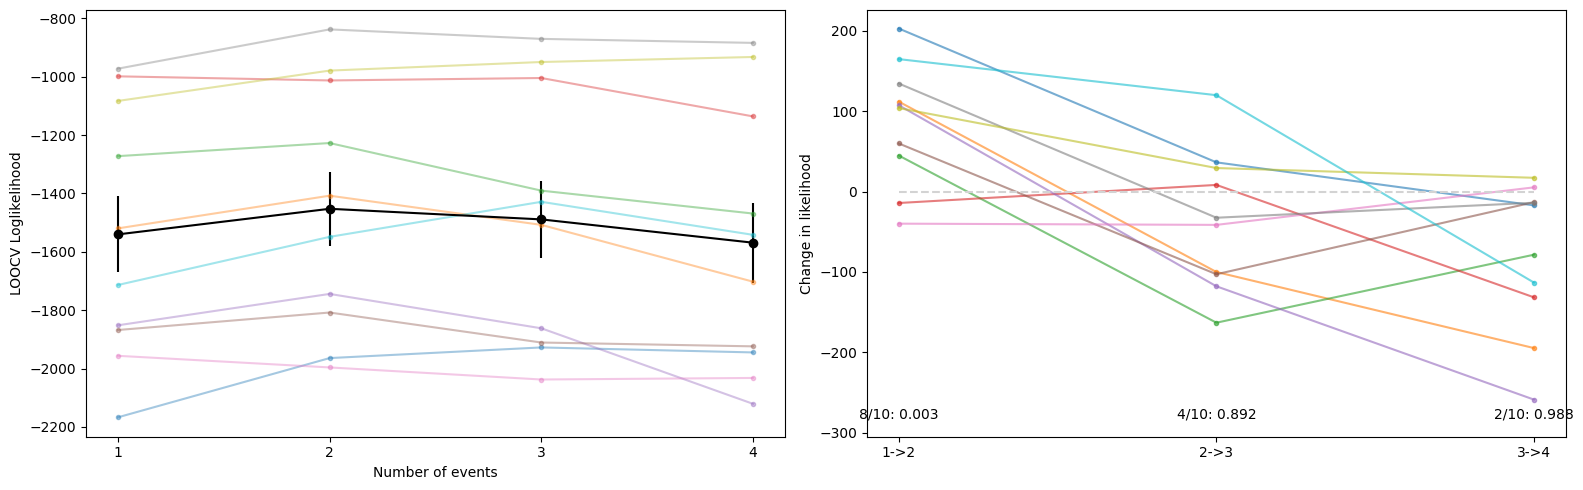

In [15]:
hmp.visu.plot_loocv(loocv_model,
                    pvals = True,
                    test  = 't-test',
                    indiv = True,
                    mean  = True)

# loocv backward

In [16]:
n_events = len(backward_model.n_events)
correct_loocv_model = hmp.loocv.loocv_backward(init,
                                               hmp_data,
                                               max_events = n_events,
                                               # cpus = cpus
                                              )

Calculating estimates with func <function backward_func at 0x128fc0900> and args [4, 0, 1, 'random', 0.0001, 1000.0].
	Estimating model for all participants except sub-LTP246
Estimating all solutions for maximal number of events (4) with 1 pre-defined starting point and 0 random starting points
Estimating all solutions for 3 events
Estimating all solutions for 2 events
Estimating all solutions for 1 events


/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/models.py:1177: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'stage' ('stage',) The recommendation is to set join explicitly for this case.
  event_loo_results = xr.concat(event_loo_results, dim="n_events")
/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/models.py:1177: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'event' ('event',) The recommendation is to set join explicitly for this case.
  event_loo_results = xr.concat(event_loo_results, dim=

	Estimating model for all participants except sub-LTP269
Estimating all solutions for maximal number of events (4) with 1 pre-defined starting point and 0 random starting points
Estimating all solutions for 3 events
Estimating all solutions for 2 events
Estimating all solutions for 1 events


/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/models.py:1177: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'stage' ('stage',) The recommendation is to set join explicitly for this case.
  event_loo_results = xr.concat(event_loo_results, dim="n_events")
/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/models.py:1177: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'event' ('event',) The recommendation is to set join explicitly for this case.
  event_loo_results = xr.concat(event_loo_results, dim=

	Estimating model for all participants except sub-LTP279
Estimating all solutions for maximal number of events (4) with 1 pre-defined starting point and 0 random starting points
Estimating all solutions for 3 events
Estimating all solutions for 2 events
Estimating all solutions for 1 events


...

	Estimating model for all participants except sub-LTP323
Estimating all solutions for maximal number of events (4) with 1 pre-defined starting point and 0 random starting points
Estimating all solutions for 3 events
Estimating all solutions for 2 events
Estimating all solutions for 1 events


/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/models.py:1177: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'stage' ('stage',) The recommendation is to set join explicitly for this case.
  event_loo_results = xr.concat(event_loo_results, dim="n_events")
/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/models.py:1177: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'event' ('event',) The recommendation is to set join explicitly for this case.
  event_loo_results = xr.concat(event_loo_results, dim=

	Estimating model for all participants except sub-LTP327
Estimating all solutions for maximal number of events (4) with 1 pre-defined starting point and 0 random starting points
Estimating all solutions for 3 events
Estimating all solutions for 2 events
Estimating all solutions for 1 events


/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/models.py:1177: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'stage' ('stage',) The recommendation is to set join explicitly for this case.
  event_loo_results = xr.concat(event_loo_results, dim="n_events")
/opt/anaconda3/envs/mne/lib/python3.13/site-packages/hmp/models.py:1177: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'event' ('event',) The recommendation is to set join explicitly for this case.
  event_loo_results = xr.concat(event_loo_results, dim=


Calculating likelihood for backward estimation models with 4 to 1 event(s)
  Calculating likelihood for backward estimation model with 4 event(s)
	Calculating likelihood for participant sub-LTP246
	Calculating likelihood for participant sub-LTP269
	Calculating likelihood for participant sub-LTP279
	Calculating likelihood for participant sub-LTP285
	Calculating likelihood for participant sub-LTP295
	Calculating likelihood for participant sub-LTP303
	Calculating likelihood for participant sub-LTP310
	Calculating likelihood for participant sub-LTP322
	Calculating likelihood for participant sub-LTP323
	Calculating likelihood for participant sub-LTP327
  Calculating likelihood for backward estimation model with 3 event(s)
	Calculating likelihood for participant sub-LTP246
	Calculating likelihood for participant sub-LTP269
	Calculating likelihood for participant sub-LTP279
	Calculating likelihood for participant sub-LTP285
	Calculating likelihood for participant sub-LTP295
	Calculating like

[TtestResult(statistic=np.float64(2.718538923653219), pvalue=np.float64(0.01183217372519577), df=np.int64(9)),
 TtestResult(statistic=np.float64(-4.232215925872203), pvalue=np.float64(0.9989002963068482), df=np.int64(9)),
 TtestResult(statistic=np.float64(-0.6446181601162179), pvalue=np.float64(0.7323712062530998), df=np.int64(9))]

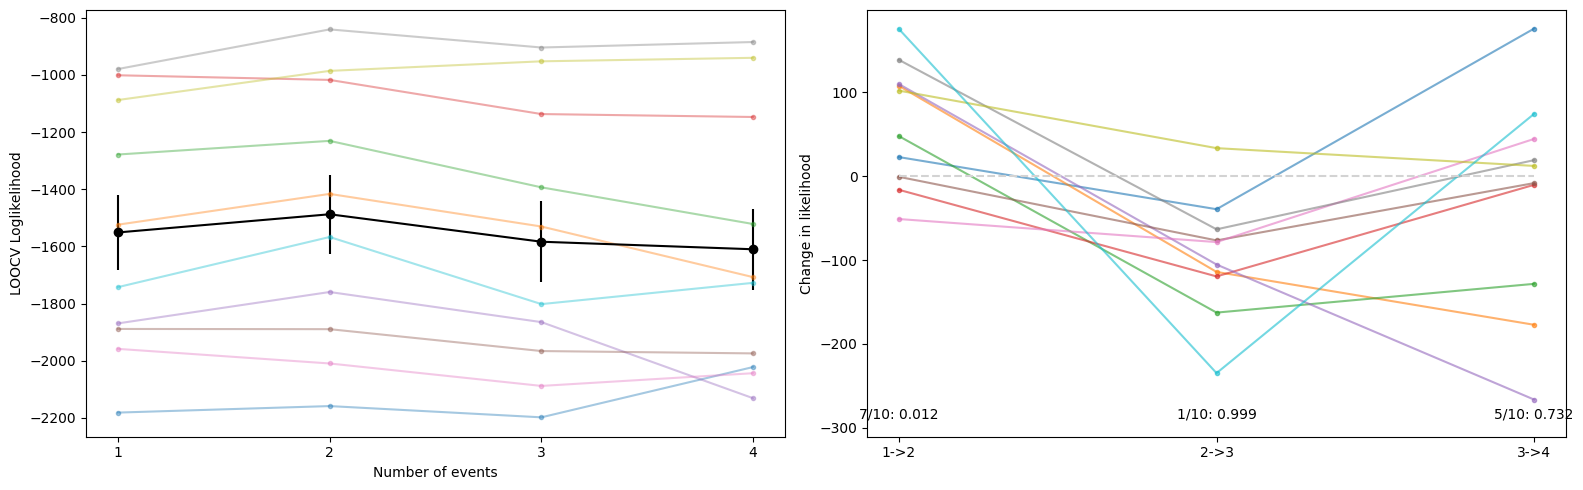

In [17]:
hmp.visu.plot_loocv(correct_loocv_model[0],
                    pvals = True,
                    test  = 't-test',
                    indiv = True,
                    mean  = True)

# topo plot

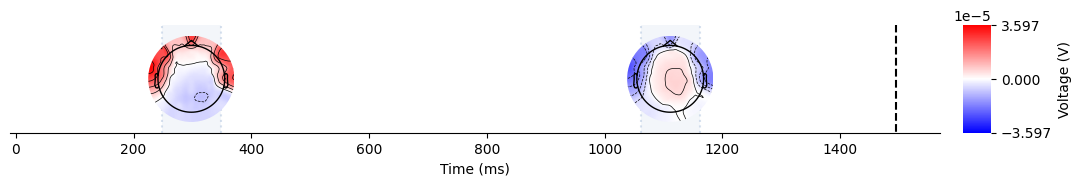

In [18]:
n_events = 2
final_model = backward_model.sel(n_events=n_events)
hmp.visu.plot_topo_timecourse(epoch_data, final_model, info, init, as_time=True,
                              #vmin=-1e-13, vmax=1e-13, 
                              magnify=2, contours=6,
                              # cmap='Spectral_r', event_lines='tab:orange')
                              cmap='bwr', event_lines='lightsteelblue')